In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix

In [3]:
data = pd.read_csv("heart_disease.csv")
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
data.shape

(2181, 14)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2181 entries, 0 to 2180
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2181 non-null   int64  
 1   sex       2181 non-null   int64  
 2   cp        2181 non-null   int64  
 3   trestbps  2181 non-null   object 
 4   chol      2181 non-null   object 
 5   fbs       2181 non-null   object 
 6   restecg   2181 non-null   object 
 7   thalachh  2181 non-null   object 
 8   exang     2181 non-null   object 
 9   oldpeak   2181 non-null   float64
 10  slope     2181 non-null   object 
 11  ca        2181 non-null   object 
 12  thal      2181 non-null   object 
 13  target    2181 non-null   int64  
dtypes: float64(1), int64(4), object(9)
memory usage: 238.7+ KB


In [6]:
"""
 In this data set, many attributes are object data type and in that,
 numeric data is present in text format, so we need to convert it into float datatype
"""

obj_cols = data.keys().drop(['age','sex','cp','oldpeak','target'])

for col in obj_cols:
    data[col] = pd.to_numeric(data[col], errors='coerce').astype('float64')

data[obj_cols].head()

,trestbps,chol,fbs,restecg,thalachh,exang,slope,ca,thal
0,145.0,233.0,1.0,0.0,150.0,0.0,0.0,0.0,1.0
1,130.0,250.0,0.0,1.0,187.0,0.0,0.0,0.0,2.0
2,130.0,204.0,0.0,0.0,172.0,0.0,2.0,0.0,2.0
3,120.0,236.0,0.0,1.0,178.0,0.0,2.0,0.0,2.0
4,120.0,354.0,0.0,1.0,163.0,1.0,2.0,0.0,2.0


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2181 entries, 0 to 2180
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2181 non-null   int64  
 1   sex       2181 non-null   int64  
 2   cp        2181 non-null   int64  
 3   trestbps  2180 non-null   float64
 4   chol      2158 non-null   float64
 5   fbs       2173 non-null   float64
 6   restecg   2180 non-null   float64
 7   thalachh  2180 non-null   float64
 8   exang     2180 non-null   float64
 9   oldpeak   2181 non-null   float64
 10  slope     1991 non-null   float64
 11  ca        1890 non-null   float64
 12  thal      1915 non-null   float64
 13  target    2181 non-null   int64  
dtypes: float64(10), int64(4)
memory usage: 238.7 KB


In [8]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145.0,233.0,1.0,0.0,150.0,0.0,2.3,0.0,0.0,1.0,1
1,37,1,2,130.0,250.0,0.0,1.0,187.0,0.0,3.5,0.0,0.0,2.0,1
2,41,0,1,130.0,204.0,0.0,0.0,172.0,0.0,1.4,2.0,0.0,2.0,1
3,56,1,1,120.0,236.0,0.0,1.0,178.0,0.0,0.8,2.0,0.0,2.0,1
4,57,0,0,120.0,354.0,0.0,1.0,163.0,1.0,0.6,2.0,0.0,2.0,1


In [9]:
data.max()

,0
age,77.0
sex,1.0
cp,3.0
trestbps,200.0
chol,603.0
fbs,1.0
restecg,2.0
thalachh,202.0
exang,1.0
oldpeak,6.2


In [10]:
data.mean()

,0
age,53.477762
sex,0.693260
cp,1.248968
trestbps,131.679817
chol,247.366543
fbs,0.138058
restecg,0.546789
thalachh,148.064220
exang,0.327523
oldpeak,0.990509


In [11]:
data.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,1
chol,23
fbs,8
restecg,1
thalachh,1
exang,1
oldpeak,0


In [12]:
# filling all the null values of trestbps, chol, fbs, restecg, thalachh, exang, slope, ca, thal with median
data.fillna(data.median(), inplace=True)
data.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalachh,0
exang,0
oldpeak,0


In [13]:
data.duplicated().sum()

np.int64(1287)

In [14]:
data.drop_duplicates(inplace=True)
data.shape

(894, 14)

In [15]:
data.head(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145.0,233.0,1.0,0.0,150.0,0.0,2.3,0.0,0.0,1.0,1
1,37,1,2,130.0,250.0,0.0,1.0,187.0,0.0,3.5,0.0,0.0,2.0,1


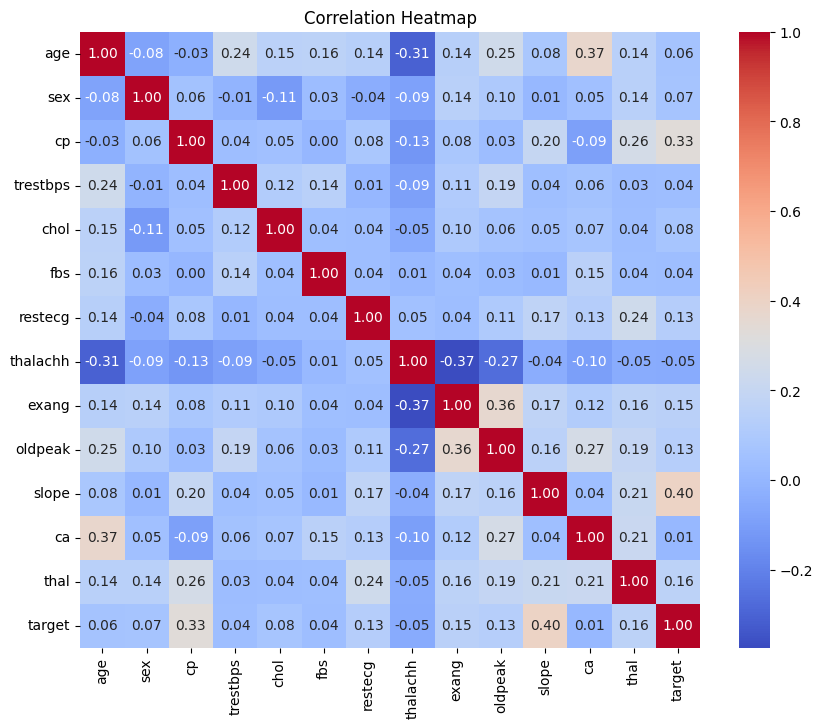

In [16]:
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [17]:
X = data.drop(columns=['target'])
y = data['target']

In [18]:
# Scaling all the attributes using Standard Scaler

scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal
0,1.162746,0.657794,1.185378,0.744976,-0.284910,2.655947,-0.756203,0.169104,-0.694685,1.254768,-2.437959,-0.546769,-1.195308
1,-1.663149,0.657794,0.297090,-0.111296,0.016984,-0.376514,0.564198,1.731128,-0.694685,2.340957,-2.437959,-0.546769,-0.610091
2,-1.228396,-1.520234,-0.591199,-0.111296,-0.799904,-0.376514,-0.756203,1.097875,-0.694685,0.440125,0.991680,-0.546769,-0.610091
3,0.401928,0.657794,-0.591199,-0.682144,-0.231634,-0.376514,0.564198,1.351176,-0.694685,-0.102969,0.991680,-0.546769,-0.610091
4,0.510616,-1.520234,-1.479487,-0.682144,1.863860,-0.376514,0.564198,0.717923,1.439502,-0.284001,0.991680,-0.546769,-0.610091


In [19]:
# Spliting the input 'X' and the target 'y' dataset into training and testing datasets

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [20]:
y_train_clean = y_train.astype(int)
y_test_clean = y_test.astype(int)

model_reg = LogisticRegression()
model_reg.fit(x_train, y_train_clean)

y_reg_pred = model_reg.predict(x_test)


In [21]:
# Calculating evaluation metrics of Logistic Reg.

acc_reg = accuracy_score(y_test_clean, y_reg_pred)
pre_reg = precision_score(y_test_clean, y_reg_pred)
rec_reg = recall_score(y_test_clean, y_reg_pred)
f1_reg = f1_score(y_test_clean, y_reg_pred)

print(acc_reg, pre_reg, rec_reg, f1_reg)

0.6480446927374302 0.5774647887323944 0.5540540540540541 0.5655172413793104


In [22]:
# Calculating confusion metrics of Logistic Reg.

y_test_reg_pred = model_reg.predict(x_test)

cm_reg = confusion_matrix(y_test_clean, y_test_reg_pred)
cm_reg

array([[75, 30],
       [33, 41]])

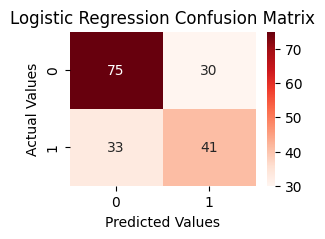

In [23]:
plt.figure(figsize=(3, 2))
sns.heatmap(cm_reg, annot=True, cmap='Reds', fmt='g')
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [24]:
model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(x_train, y_train_clean)

y_knn_pred = model_knn.predict(x_test)


In [25]:
# Calculating evaluation metrics of K Nearest Neighbor (KNN).

acc_knn = accuracy_score(y_test_clean, y_knn_pred)
pre_knn = precision_score(y_test_clean, y_knn_pred)
rec_knn = recall_score(y_test_clean, y_knn_pred)
f1_knn = f1_score(y_test_clean, y_knn_pred)

print(acc_knn, pre_knn, rec_knn, f1_knn)

0.7206703910614525 0.6714285714285714 0.6351351351351351 0.6527777777777778


In [26]:
# Calculating Confusion metrics of K Nearest Neighbor (KNN).

y_test_knn_pred = model_knn.predict(x_test)

cm_knn = confusion_matrix(y_test_clean, y_test_knn_pred)
cm_knn

array([[82, 23],
       [27, 47]])

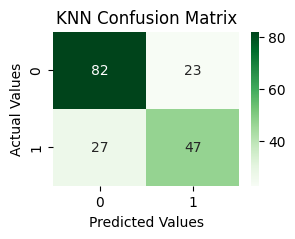

In [27]:
plt.figure(figsize=(3, 2))
sns.heatmap(cm_knn, annot=True, cmap='Greens', fmt='g')
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [28]:
model_dt = DecisionTreeClassifier(max_depth=4, random_state=42)
model_dt.fit(x_train, y_train_clean)

y_dt_pred = model_dt.predict(x_test)


In [29]:
# Calculating evaluation metrics of Decision Tree

acc_dt = accuracy_score(y_test_clean, y_dt_pred)
pre_dt = precision_score(y_test_clean, y_dt_pred)
rec_dt = recall_score(y_test_clean, y_dt_pred)
f1_dt = f1_score(y_test_clean, y_dt_pred)

print(acc_dt, pre_dt, rec_dt, f1_dt)

0.7541899441340782 0.7586206896551724 0.5945945945945946 0.6666666666666666


In [30]:
# Calculating Confusion metrics of Decision Tree

y_test_dt_pred = model_dt.predict(x_test)

cm_dt = confusion_matrix(y_test_clean, y_test_dt_pred)
cm_dt

array([[91, 14],
       [30, 44]])

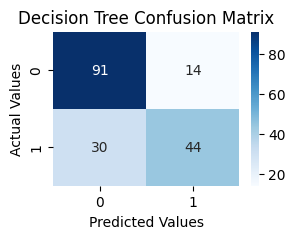

In [31]:
plt.figure(figsize=(3, 2))
sns.heatmap(cm_dt, annot=True, cmap='Blues', fmt='g')
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [32]:
# compare all the three model in tabular form

model_list = ['Logistic Regression', 'KNN', 'Decision Tree']
accuracy = [acc_reg, acc_knn, acc_dt]
precision = [pre_reg, pre_knn, pre_dt]
recall = [rec_reg, rec_knn, rec_dt]
f1_score = [f1_reg, f1_knn, f1_dt]

model_compare = pd.DataFrame({
    "Model Name": model_list,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1_score
})

cols_to_format = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
model_compare[cols_to_format] = (model_compare[cols_to_format] * 100).round(1).astype(str) + '%'

model_compare.to_csv('model_compare.csv', index=False)



# 3 Model, 1 Dataset
  

In [33]:
model_compare

,Model Name,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,64.8%,57.7%,55.4%,56.6%
1,KNN,72.1%,67.1%,63.5%,65.3%
2,Decision Tree,75.4%,75.9%,59.5%,66.7%


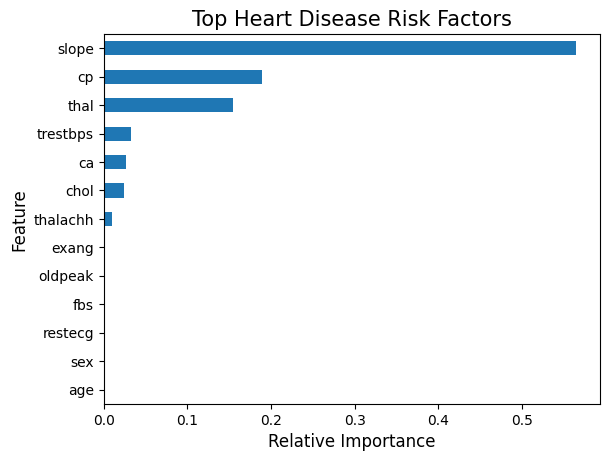

In [34]:
pd.Series(model_dt.feature_importances_, index=X.columns).sort_values().plot(kind='barh')
plt.title('Top Heart Disease Risk Factors', fontsize=15)
plt.xlabel('Relative Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

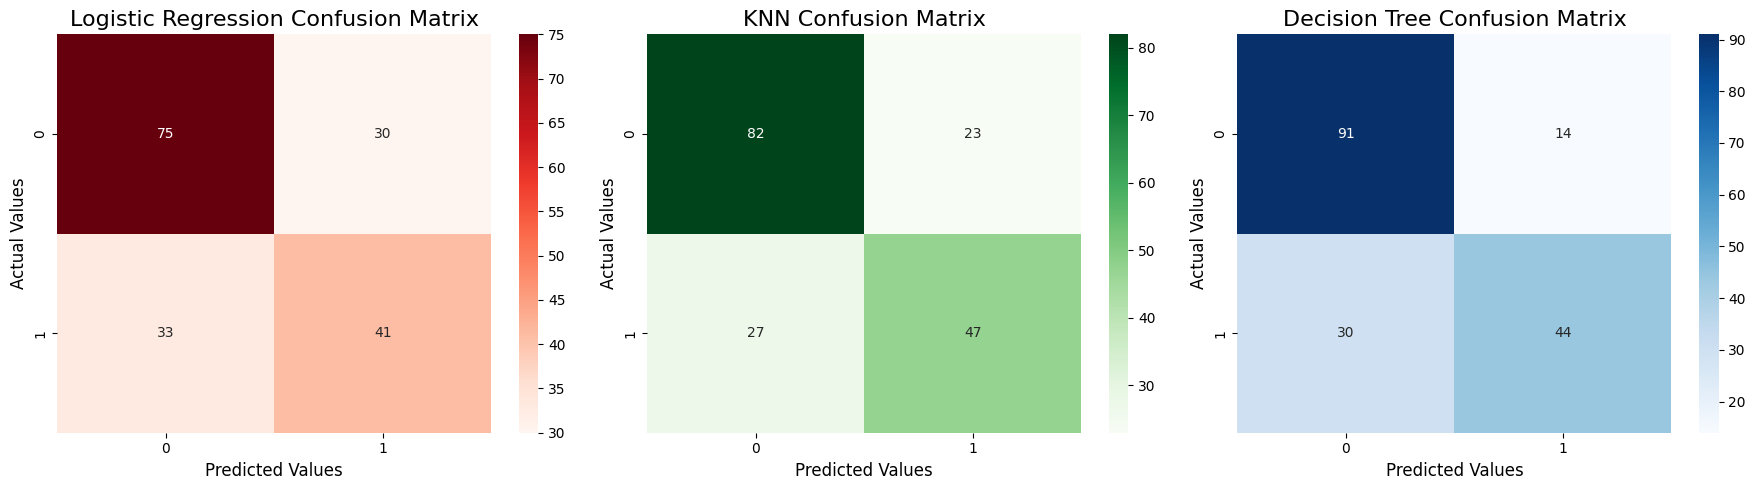

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Logistic Regression Heatmap
sns.heatmap(cm_reg, annot=True, cmap='Reds', fmt='g', ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].title.set_fontsize(16)
axes[0].set_xlabel('Predicted Values')
axes[0].set_ylabel('Actual Values')
axes[0].xaxis.label.set_fontsize(12)
axes[0].yaxis.label.set_fontsize(12)


# KNN Heatmap
sns.heatmap(cm_knn, annot=True, cmap='Greens', fmt='g', ax=axes[1])
axes[1].set_title('KNN Confusion Matrix')
axes[1].title.set_fontsize(16)
axes[1].set_xlabel('Predicted Values')
axes[1].set_ylabel('Actual Values')
axes[1].xaxis.label.set_fontsize(12)
axes[1].yaxis.label.set_fontsize(12)

# Decision Tree Heatmap
sns.heatmap(cm_dt, annot=True, cmap='Blues', fmt='g', ax=axes[2])
axes[2].set_title('Decision Tree Confusion Matrix')
axes[2].title.set_fontsize(16)
axes[2].set_xlabel('Predicted Values')
axes[2].set_ylabel('Actual Values')
axes[2].xaxis.label.set_fontsize(12)
axes[2].yaxis.label.set_fontsize(12)


plt.tight_layout()
plt.show()

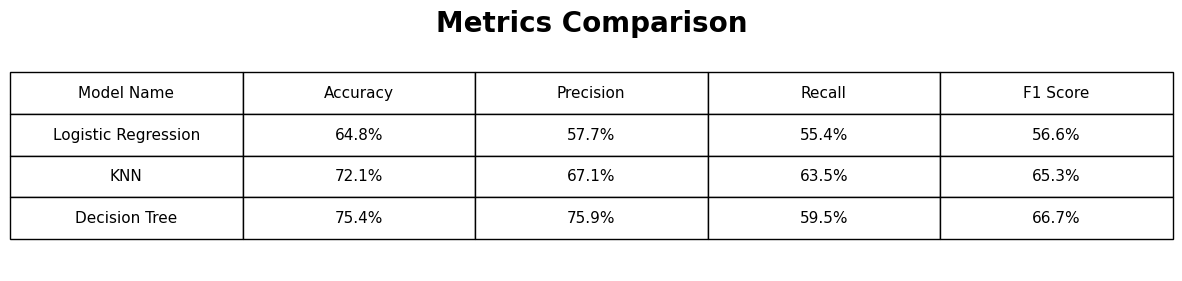

In [36]:
fig, ax = plt.subplots(figsize=(15, 3))
ax.axis('off')
ax.axis('tight')

table = ax.table(cellText=model_compare.values, colLabels=model_compare.columns, loc='center', cellLoc='center')

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.5)

ax.set_title('Metrics Comparison', fontdict={'fontsize': 20, 'fontweight': 'bold'})

plt.savefig('model_compare.png', bbox_inches='tight', dpi=300)
plt.show()